# Cell 1: Imports and experiment setup

In [16]:

# Cell 1: Imports and experiment setup

import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.pipeline import Pipeline

warnings.filterwarnings("default")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports successful.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Imports successful.
NumPy: 2.3.5
Pandas: 2.3.3


# Cell 2: Configure paths and load train/test datasets

In [17]:

# Cell 2: Configure paths and load train/test datasets

FEATURE_DIR = Path(
    r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT"
)

MODEL_DIR = FEATURE_DIR / "KNN_Model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = FEATURE_DIR / "pca_swt_train.csv"
TEST_FILE = FEATURE_DIR / "pca_swt_test.csv"

assert TRAIN_FILE.exists(), f"Training file not found: {TRAIN_FILE}"
assert TEST_FILE.exists(), f"Test file not found: {TEST_FILE}"

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())

print("\nModel output directory:", MODEL_DIR)


Training dataset: (3883, 33)
Testing dataset: (830, 33)

Training columns:
['filename', 'split', 'label', 'SWT_PCA_01', 'SWT_PCA_02', 'SWT_PCA_03', 'SWT_PCA_04', 'SWT_PCA_05', 'SWT_PCA_06', 'SWT_PCA_07', 'SWT_PCA_08', 'SWT_PCA_09', 'SWT_PCA_10', 'SWT_PCA_11', 'SWT_PCA_12', 'SWT_PCA_13', 'SWT_PCA_14', 'SWT_PCA_15', 'SWT_PCA_16', 'SWT_PCA_17', 'SWT_PCA_18', 'SWT_PCA_19', 'SWT_PCA_20', 'SWT_PCA_21', 'SWT_PCA_22', 'SWT_PCA_23', 'SWT_PCA_24', 'SWT_PCA_25', 'SWT_PCA_26', 'SWT_PCA_27', 'SWT_PCA_28', 'SWT_PCA_29', 'SWT_PCA_30']

Training class distribution:
label
pituitary     1455
meningioma    1320
glioma        1108
Name: count, dtype: int64

Testing class distribution:
label
meningioma    301
pituitary     295
glioma        234
Name: count, dtype: int64

Model output directory: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\KNN_Model


# Cell 3: Validate datasets and prepare model inputs

In [18]:

# Cell 3: Validate datasets and prepare model inputs

metadata_cols = ["filename", "split", "label"]

feature_cols = [
    col for col in train_df.columns
    if col not in metadata_cols
]

# Check that train and test have identical feature columns
test_feature_cols = [
    col for col in test_df.columns
    if col not in metadata_cols
]

assert feature_cols == test_feature_cols, "Feature columns do not match!"
assert train_df["split"].eq("train").all(), "Unexpected split in training data!"
assert test_df["split"].eq("test").all(), "Unexpected split in test data!"

# Validate numerical features
X_train_df = train_df[feature_cols]
X_test_df = test_df[feature_cols]

assert X_train_df.notna().all().all(), "Missing training feature values!"
assert X_test_df.notna().all().all(), "Missing test feature values!"

assert np.isfinite(X_train_df.to_numpy()).all(), "Non-finite training values!"
assert np.isfinite(X_test_df.to_numpy()).all(), "Non-finite test values!"

# Prepare arrays
X_train = X_train_df.to_numpy(dtype=np.float64)
y_train = train_df["label"].to_numpy()

X_test = X_test_df.to_numpy(dtype=np.float64)
y_test = test_df["label"].to_numpy()

classes = np.sort(np.unique(y_train))

assert set(y_train) == set(y_test), "Train/test classes do not match!"

print("Feature count:", len(feature_cols))
print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Classes:", classes.tolist())
print("Missing values: 0")
print("Infinite values: 0")
print("All checks passed.")


Feature count: 30
Training samples: 3883
Test samples: 830
Classes: ['glioma', 'meningioma', 'pituitary']
Missing values: 0
Infinite values: 0
All checks passed.


# Cell 4: Baseline KNN model

In [19]:

# Cell 4: Baseline KNN model

baseline_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski",
    p=2,
    n_jobs=-1
)

start_time = time.time()
baseline_knn.fit(X_train, y_train)
baseline_train_time = time.time() - start_time

# Training-set predictions are diagnostic only, not the final evaluation
train_predictions = baseline_knn.predict(X_train)

# Cross-validation on training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores = cross_val_score(
    baseline_knn,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Baseline KNN: k=5, distance weighting, Euclidean distance")
print(f"Fit time: {baseline_train_time:.3f} seconds")
print(f"Training accuracy (diagnostic): "
      f"{accuracy_score(y_train, train_predictions):.4f}")
print(f"5-fold CV macro-F1: {cv_scores.mean():.4f} "
      f"+/- {cv_scores.std():.4f}")
print("Fold scores:", np.round(cv_scores, 4))


Baseline KNN: k=5, distance weighting, Euclidean distance
Fit time: 0.006 seconds
Training accuracy (diagnostic): 1.0000
5-fold CV macro-F1: 0.7305 +/- 0.0092
Fold scores: [0.7411 0.72   0.7408 0.7299 0.7209]


# Cell 5: Hyperparameter tuning using training data only

In [20]:

# Cell 5: Hyperparameter tuning using training data only

param_grid = {
    "n_neighbors": list(range(3, 32, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["minkowski"],
    "p": [1, 2, 3],
    "leaf_size": [15, 30, 45]
}

knn_search = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=1),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

start_time = time.time()
knn_search.fit(X_train, y_train)
tuning_time = time.time() - start_time

print("\nTuning completed.")
print(f"Elapsed time: {tuning_time / 60:.2f} minutes")
print("Best parameters:")
print(knn_search.best_params_)
print(f"Best CV macro-F1: {knn_search.best_score_:.4f}")

results_df = pd.DataFrame(knn_search.cv_results_)
results_df = results_df.sort_values(
    "rank_test_score"
).reset_index(drop=True)

print("\nTop 10 configurations:")
display(
    results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(10)
)


Fitting 5 folds for each of 270 candidates, totalling 1350 fits

Tuning completed.
Elapsed time: 20.27 minutes
Best parameters:
{'leaf_size': 15, 'metric': 'minkowski', 'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
Best CV macro-F1: 0.7640

Top 10 configurations:


C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [       nan 0.73118502 0.70292863 0.71616701        nan 0.71243322
        nan 0.73971081 0.72025095 0.73051856        nan 0.72153888
        nan 0.74776825 0.73174372 0.74362853        nan 0.73708515
        nan 0.75267098 0.73853335 0.74786047        nan 0.73904233
        nan 0.75568894 0.74132079 0.74838062        nan 0.73661785
        nan 0.75987999 0.74462241 0.74785082        nan 0.74342989
        nan 0.76027726 0.74690652 0.74890077        nan 0.74540927
        nan 0.75906356 0.74445479 0.7514181         nan 0.74644799
        nan 0.76325271 0.74902895 0.75047806        nan 0.74812522
        nan 0.76397963 0.74495402 0.75044098        nan 0.75028084
        nan 0.75806966 0.74610406 0.75052514        nan 0.75057657
        nan 0.76160101 0.7481452  0.75230901        nan 0.74972203
        nan 0.75944083 0.75085376 0.75503276        

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.763980,0.011942,1.0,"{'leaf_size': 45, 'metric': 'minkowski', 'n_ne..."
1,1,0.763980,0.011942,1.0,"{'leaf_size': 30, 'metric': 'minkowski', 'n_ne..."
2,1,0.763980,0.011942,1.0,"{'leaf_size': 15, 'metric': 'minkowski', 'n_ne..."
3,4,0.763253,0.009888,1.0,"{'leaf_size': 45, 'metric': 'minkowski', 'n_ne..."
4,4,0.763253,0.009888,1.0,"{'leaf_size': 30, 'metric': 'minkowski', 'n_ne..."
5,4,0.763253,0.009888,1.0,"{'leaf_size': 15, 'metric': 'minkowski', 'n_ne..."
6,7,0.761601,0.012228,1.0,"{'leaf_size': 15, 'metric': 'minkowski', 'n_ne..."
7,7,0.761601,0.012228,1.0,"{'leaf_size': 30, 'metric': 'minkowski', 'n_ne..."
8,7,0.761601,0.012228,1.0,"{'leaf_size': 45, 'metric': 'minkowski', 'n_ne..."
9,10,0.760994,0.016813,1.0,"{'leaf_size': 15, 'metric': 'minkowski', 'n_ne..."


# Cell 6: Evaluate the best KNN model on the test set

In [21]:

# Cell 6: Evaluate the best KNN model on the test set

best_knn = knn_search.best_estimator_

# Predict test labels and class probabilities
y_test_pred = best_knn.predict(X_test)
y_test_proba = best_knn.predict_proba(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")

print("TUNED KNN — TEST SET EVALUATION")
print("=" * 45)
print(f"Best CV Macro-F1:       {knn_search.best_score_:.4f}")
print(f"Test Accuracy:          {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Test Macro-F1:          {test_macro_f1:.4f}")
print(f"Test Weighted F1:       {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=classes,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


TUNED KNN — TEST SET EVALUATION
Best CV Macro-F1:       0.7640
Test Accuracy:          0.7819
Test Balanced Accuracy: 0.7787
Test Macro-F1:          0.7801
Test Weighted F1:       0.7814

Classification Report:
              precision    recall  f1-score   support

      glioma     0.7982    0.7436    0.7699       234
  meningioma     0.8254    0.8638    0.8442       301
   pituitary     0.7239    0.7288    0.7264       295

    accuracy                         0.7819       830
   macro avg     0.7825    0.7787    0.7801       830
weighted avg     0.7816    0.7819    0.7814       830



# Cell 7: Inspect class-wise prediction errors

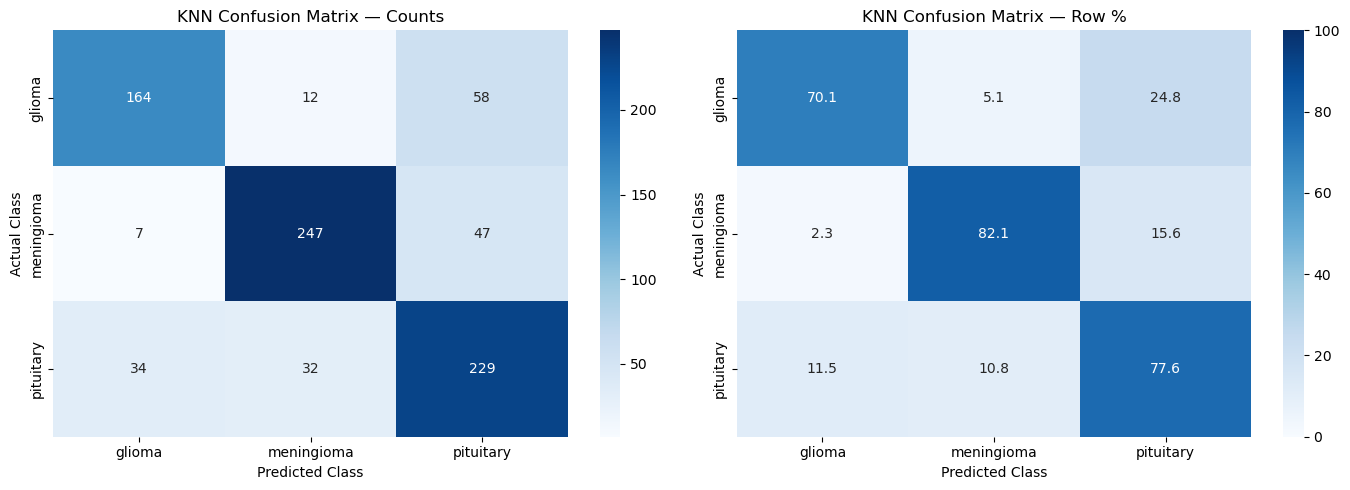

In [7]:

# Cell 7: Inspect class-wise prediction errors

cm = confusion_matrix(y_test, y_test_pred, labels=classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw number of predictions
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix — Counts")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Percentage of each actual class correctly/incorrectly classified
cm_normalized = cm / cm.sum(axis=1, keepdims=True) * 100

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    vmin=0,
    vmax=100,
    ax=axes[1]
)
axes[1].set_title("KNN Confusion Matrix — Row %")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


# Cell 8: Compare KNN with PCA features vs all original SWT features

In [8]:

# Cell 8: Compare KNN with PCA features vs all original SWT features

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Load the original 32-dimensional SWT feature data
SWT_TRAIN_FILE = FEATURE_DIR / "swt_train.csv"

assert SWT_TRAIN_FILE.exists(), (
    f"Original SWT training features not found: {SWT_TRAIN_FILE}"
)

swt_train_df = pd.read_csv(SWT_TRAIN_FILE)

metadata_cols = ["filename", "split", "label"]
swt_feature_cols = [
    col for col in swt_train_df.columns
    if col not in metadata_cols
]

X_swt = swt_train_df[swt_feature_cols].to_numpy(dtype=np.float64)
y_swt = swt_train_df["label"].to_numpy()

assert X_swt.shape[1] == 32, (
    f"Expected 32 SWT features, found {X_swt.shape[1]}"
)
assert np.isfinite(X_swt).all(), "SWT features contain invalid values"

# Scaling is fitted independently inside each CV fold to prevent leakage
swt_knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_jobs=1))
])

swt_param_grid = {
    "knn__n_neighbors": [5, 9, 13, 17, 21, 25, 31, 35, 41],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["minkowski"],
    "knn__p": [1, 2]
}

swt_search = GridSearchCV(
    estimator=swt_knn_pipeline,
    param_grid=swt_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

start_time = time.time()
swt_search.fit(X_swt, y_swt)
swt_tuning_time = time.time() - start_time

print(f"\nTuning time: {swt_tuning_time / 60:.2f} minutes")
print(f"Best CV macro-F1 using all SWT features: "
      f"{swt_search.best_score_:.4f}")
print(f"Best parameters: {swt_search.best_params_}")

swt_results_df = (
    pd.DataFrame(swt_search.cv_results_)
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

display(
    swt_results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(10)
)


Fitting 5 folds for each of 36 candidates, totalling 180 fits


C:\Users\harsh\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Tuning time: 0.34 minutes
Best CV macro-F1 using all SWT features: 0.7603
Best parameters: {'knn__metric': 'minkowski', 'knn__n_neighbors': 21, 'knn__p': 1, 'knn__weights': 'distance'}


C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [       nan 0.74928673 0.72156789 0.73160049        nan 0.7564321
 0.73906133 0.74686212        nan 0.75129411 0.74453463 0.74637359
        nan 0.75641517 0.74416757 0.75012657        nan 0.76027083
 0.74546327 0.74959391        nan 0.75804357 0.74772319 0.75288543
        nan 0.75453181 0.74681074 0.75189092        nan 0.75425456
 0.74732294 0.7506436         nan 0.75353991 0.74770253 0.75255814]
  warnings.warn(
C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the train scores are non-finite: [       nan 1.         0.82421949 1.                nan 1.
 0.80449171 1.                nan 1.         0.79441918 1.
        nan 1.         0.78198365 1.                nan 1.
 0.77642946 1.                nan 1.         0.77659796 1.
        nan 1.         0.7733843  1.                nan 

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.760271,0.007989,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
1,2,0.758044,0.012248,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
2,3,0.756432,0.015552,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
3,4,0.756415,0.012838,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
4,5,0.754532,0.008856,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
5,6,0.754255,0.011470,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
6,7,0.753540,0.011655,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
7,8,0.752885,0.015407,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
8,9,0.752558,0.009054,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."
9,10,0.751891,0.014613,1.0,"{'knn__metric': 'minkowski', 'knn__n_neighbors..."


# Cell 9: Final test evaluation for KNN using all SWT features

In [22]:

# Cell 9: Final test evaluation for KNN using all SWT features

SWT_TEST_FILE = FEATURE_DIR / "swt_test.csv"

assert SWT_TEST_FILE.exists(), (
    f"Original SWT test features not found: {SWT_TEST_FILE}"
)

swt_test_df = pd.read_csv(SWT_TEST_FILE)

test_swt_feature_cols = [
    col for col in swt_test_df.columns
    if col not in ["filename", "split", "label"]
]

assert swt_feature_cols == test_swt_feature_cols
assert swt_test_df["split"].eq("test").all()

X_swt_test = swt_test_df[swt_feature_cols].to_numpy(dtype=np.float64)
y_swt_test = swt_test_df["label"].to_numpy()

assert np.isfinite(X_swt_test).all(), "Test features contain invalid values"

# GridSearchCV already refitted the best pipeline on all training data
best_swt_knn = swt_search.best_estimator_

y_swt_pred = best_swt_knn.predict(X_swt_test)

swt_test_accuracy = accuracy_score(y_swt_test, y_swt_pred)
swt_test_balanced_accuracy = balanced_accuracy_score(y_swt_test, y_swt_pred)
swt_test_macro_f1 = f1_score(y_swt_test, y_swt_pred, average="macro")
swt_test_weighted_f1 = f1_score(y_swt_test, y_swt_pred, average="weighted")

print("KNN — ALL 32 SWT FEATURES")
print("=" * 45)
print(f"CV Macro-F1:            {swt_search.best_score_:.4f}")
print(f"Test Accuracy:          {swt_test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {swt_test_balanced_accuracy:.4f}")
print(f"Test Macro-F1:          {swt_test_macro_f1:.4f}")
print(f"Test Weighted F1:       {swt_test_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_swt_test,
        y_swt_pred,
        labels=classes,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


KNN — ALL 32 SWT FEATURES
CV Macro-F1:            0.7603
Test Accuracy:          0.8012
Test Balanced Accuracy: 0.7970
Test Macro-F1:          0.7986
Test Weighted F1:       0.8010

Classification Report:
              precision    recall  f1-score   support

      glioma     0.7991    0.7479    0.7726       234
  meningioma     0.8627    0.8771    0.8699       301
   pituitary     0.7410    0.7661    0.7533       295

    accuracy                         0.8012       830
   macro avg     0.8009    0.7970    0.7986       830
weighted avg     0.8015    0.8012    0.8010       830



In [25]:

# Save KNN model with its 30-component PCA artifacts

import joblib
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

FEATURE_DIR = Path(
    r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT"
)

MODEL_DIR = FEATURE_DIR / "knn_swt_model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load the fitted preprocessing artifacts saved by the preprocessing notebook
scaler_path = FEATURE_DIR / "swt_scaler.pkl"
pca_path = FEATURE_DIR / "swt_pca.pkl"
feature_columns_path = FEATURE_DIR / "swt_feature_columns.pkl"

assert scaler_path.exists(), f"Scaler not found: {scaler_path}"
assert pca_path.exists(), f"PCA not found: {pca_path}"
assert feature_columns_path.exists(), (
    f"Feature columns not found: {feature_columns_path}"
)

swt_scaler = joblib.load(scaler_path)
swt_pca = joblib.load(pca_path)
feature_cols = joblib.load(feature_columns_path)

assert swt_pca.n_components_ == 30, (
    f"Expected 30 PCA components, found {swt_pca.n_components_}"
)

# Save the fitted KNN classifier
best_pca_knn = knn_search.best_estimator_

joblib.dump(
    best_pca_knn,
    MODEL_DIR / "knn_swt_model.pkl"
)

# Copy the matching preprocessing artifacts into the model folder
joblib.dump(swt_scaler, MODEL_DIR / "swt_scaler.pkl")
joblib.dump(swt_pca, MODEL_DIR / "swt_pca.pkl")
joblib.dump(feature_cols, MODEL_DIR / "swt_feature_columns.pkl")

# Save evaluation metrics
metrics = {
    "model_name": "KNN SWT PCA 30",
    "pca_components": int(swt_pca.n_components_),
    "best_parameters": knn_search.best_params_,
    "cv_macro_f1": float(knn_search.best_score_),
    "test_accuracy": float(accuracy_score(y_test, y_test_pred)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_test_pred)
    ),
    "test_macro_f1": float(
        f1_score(y_test, y_test_pred, average="macro")
    ),
    "test_weighted_f1": float(
        f1_score(y_test, y_test_pred, average="weighted")
    )
}

with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

# Verify saved files
loaded_model = joblib.load(MODEL_DIR / "knn_swt_model.pkl")

print("Model and preprocessing artifacts saved successfully.")
print("Folder:", MODEL_DIR)
print("Classifier:", type(loaded_model).__name__)
print("PCA components:", swt_pca.n_components_)
print("Test accuracy:", f"{metrics['test_accuracy']:.2%}")
print("Saved files:", [p.name for p in MODEL_DIR.iterdir()])


Model and preprocessing artifacts saved successfully.
Folder: C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT\knn_swt_model
Classifier: KNeighborsClassifier
PCA components: 30
Test accuracy: 78.19%
Saved files: ['knn_swt_model.pkl', 'metrics.json', 'swt_feature_columns.pkl', 'swt_pca.pkl', 'swt_scaler.pkl']
